# Singer-Clark 2025 source data

This notebook inspects the public Dryad release for the speech-motor-cortex cursor BCI. One MATLAB file is one 3 to 5 minute task block. Neural, behavioral, decoder-output, and task-state fields share a 10 ms time base.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from neuralshed.datasets.singer_2025 import utils

## Inventory

The current release contains 51 cursor-task blocks from post-implant days 39, 202, and 468. The separate day-202 speech-only comparison file is intentionally outside `list_blocks()`.

In [2]:
blocks = utils.list_blocks()
print(f"data directory: {utils.DEFAULT_DATA_DIR}")
print(f"cursor-task blocks: {len(blocks)}")
print("sessions:", Counter(block.session for block in blocks))
print("tasks:", Counter(block.task for block in blocks))

data directory: /Volumes/seagate_0/tether/datasets/singer_2025/data/Singer2025CursorControl
cursor-task blocks: 51
sessions: Counter({'t15_day00202': 27, 't15_day00468': 18, 't15_day00039': 6})
tasks: Counter({'radial8_calibration': 21, 'simultaneous_speech_and_cursor': 21, 'grid_evaluation': 9})


## Task-specific schemas

Inspect one block from each task family. Optional click and speech fields appear only where the task used them.

In [3]:
representative = {
    task: next(block for block in blocks if block.task == task)
    for task in utils.TASK_LABELS
}
for task, block in representative.items():
    data = utils.load_block(block)
    fields = {
        key: np.asarray(value).shape
        for key, value in data.items()
        if not key.startswith("__")
    }
    print(f"\n{task}: {block.label}")
    print(f"  duration={utils.duration(block):.2f}s, trials={len(utils.trial_windows(block))}")
    print("  fields:", fields)


radial8_calibration: t15_day00039_block00_radial8_calibration_task
  duration=179.86s, trials=52
  fields: {'timestamp_sec': (17986,), 'threshold_crossings': (17986, 256), 'spike_band_power': (17986, 256), 'assist_amount': (17986,), 'cursor_position': (17986, 2), 'target_position': (17986, 2), 'trial_idx': (17986,), 'cursor_decoder_output': (17986, 2), 'trial_start_bin': (52,), 'target_radius': (), 'cursor_radius': (), 'array_label_by_electrode': (256,), 'dwell_requirement_sec': ()}

simultaneous_speech_and_cursor: t15_day00202_block02_simultaneous_speech_and_cursor_task
  duration=180.01s, trials=27
  fields: {'timestamp_sec': (18001,), 'threshold_crossings': (18001, 256), 'spike_band_power': (18001, 256), 'assist_amount': (18001,), 'cursor_position': (18001, 2), 'target_position': (18001, 2), 'trial_idx': (18001,), 'cursor_decoder_output': (18001, 2), 'trial_start_bin': (27,), 'target_presentation_bin': (27,), 'cursor_go_cue_bin': (27,), 'speech_go_cue_bin': (27,), 'trial_end_bin': 

## Shared alignment and channel layout

All continuous fields have the same number of bins. The neural axis follows `v6v`, area `4`, `55b`, and `d6v`, with 64 electrodes per array.

In [4]:
block = representative["radial8_calibration"]
print(Counter(utils.array_labels(block)))
for key in (
    "threshold_crossings",
    "spike_band_power",
    "cursor_position",
    "target_position",
    "cursor_decoder_output",
    "assist_amount",
):
    print(key, utils.get_series(block, key).shape)

Counter({'v6v': 64, '4': 64, '55b': 64, 'd6v': 64})
threshold_crossings (17986, 256)
spike_band_power (17986, 256)
cursor_position (17986, 2)
target_position (17986, 2)
cursor_decoder_output (17986, 2)
assist_amount (17986, 1)


## Cursor trajectory and assist

The plot verifies screen coordinates and shows how calibration can transition from computer assistance to closed-loop neural control.

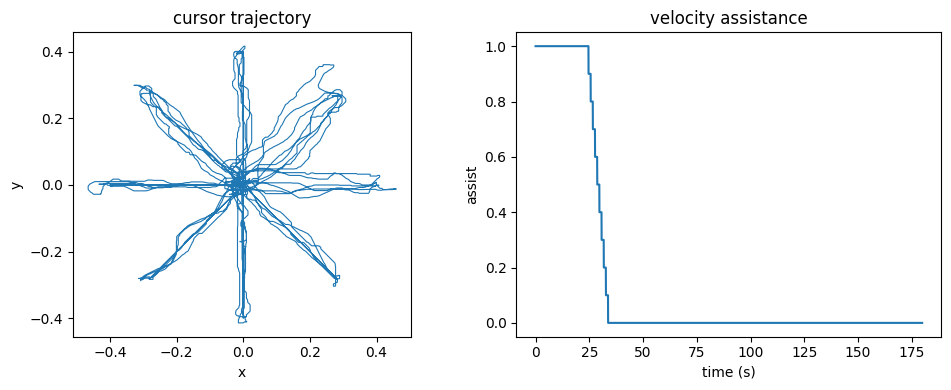

In [5]:
cursor = utils.get_series(block, "cursor_position")
assist = utils.get_series(block, "assist_amount").ravel()
time = np.arange(len(cursor)) / utils.FS

figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(cursor[:, 0], cursor[:, 1], linewidth=0.8)
axes[0].set_aspect("equal")
axes[0].set(title="cursor trajectory", xlabel="x", ylabel="y")
axes[1].plot(time, assist)
axes[1].set(title="velocity assistance", xlabel="time (s)", ylabel="assist")
plt.tight_layout()

## Trial timing

Simultaneous speech blocks expose separate target-presentation, cursor-go, speech-go, and trial-end indices. A speech-go value of `-1` means that trial had no beep.

In [6]:
sim = representative["simultaneous_speech_and_cursor"]
for key in (
    "trial_start_bin",
    "target_presentation_bin",
    "cursor_go_cue_bin",
    "speech_go_cue_bin",
    "trial_end_bin",
):
    print(key, utils.trial_field(sim, key)[:8])
print("prompts:", utils.speech_prompts(sim)[:8])
print("control block:", utils.scalar_field(sim, "is_control_block"))

trial_start_bin [  32  708 1270 1865 2441 3008 3544 4297]
target_presentation_bin [ 132  808 1370 1965 2541 3108 3644 4397]
cursor_go_cue_bin [ 280  948 1535 2106 2685 3247 3801 4551]
speech_go_cue_bin [ 370   -1   -1   -1   -1   -1 3957 4733]
trial_end_bin [ 707 1269 1864 2440 3007 3543 4296 5092]
prompts: ['choice', 'though', 'kite', 'veto', 'day', 'were', 'bah', 'bah']
control block: 0
